# Прогнозування цін на житло в Каліфорнії: як географічне групування впливає на валідацію

**Курс:** Машинне навчання (НаУКМА) **Дані:** `sklearn.datasets.fetch_california_housing`

## Питання дослідження
1. Наскільки змінюється оцінка якості регресійних моделей, якщо поділ на train/test робити **за регіонами** (`GroupKFold`), а не випадково (`KFold`)?
2. Які ознаки найважливіші за **permutation importance**, пораховано на **відкладених (тестових) фолдах**, і чи змінюється цей рейтинг при зміні схеми валідації?

**Що вважаємо відповіддю.** (а) Таблиця RMSE / MAE / R² (середнє ± std по фолдах) для всіх моделей у трьох схемах валідації. (б) Контрольний експеримент, що відділяє ефект географії від ефекту «складніших фолдів». (в) Рейтинг ознак із розкидом по фолдах для обох схем.

**Чому це важливо.** Сусідні блоки схожі за ціною (просторова автокореляція). При випадковому поділі «сусіди» потрапляють і в train, і в test, тому оцінка може бути надто оптимістичною для задачі «передбачити ціну в новому регіоні».

## Структура ноутбука
0. Налаштування → 1. Перевірка даних → 2. Регіони → 3. Базова лінія, попередня обробка, моделі → 4. Схеми валідації та порівняння → 5. Чутливість до числа регіонів → 6. Абляція (без координат) → 7. Permutation importance → 8. Аналіз помилок → 9. Підсумок чисел для README → 10. Обмеження.

Ноутбук запускається зверху вниз (`Restart & Run All`), усі результати зберігаються у `results/`, усі графіки — у `figures/`.

## 0. Налаштування та відтворюваність

In [1]:
import os
import platform
import sys
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_california_housing
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42          # єдиний сід для всього: KMeans, KFold, моделі, permutation importance
np.random.seed(RANDOM_STATE)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.13.5 | numpy 1.26.4 | pandas 2.2.3 | scikit-learn 1.6.0 | matplotlib 3.9.3


## 1. Перевірка даних
Дивимось розмір, типи, пропуски, розподіл цілі та очевидні проблеми. Ціль `MedHouseVal` — медіанна вартість будинку в блоці, в одиницях **100 000 $** (тобто 1.0 = 100 тис. $).

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
TARGET = "MedHouseVal"
FEATURES = [c for c in df.columns if c != TARGET]

print("Розмір:", df.shape)
print()
df.info()
print("\nПропуски по стовпцях:")
print(df.isnull().sum().to_string())
print("\nОпис:")
print(df.describe().T.round(3).to_string())

Розмір: (20640, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Пропуски по стовпцях:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Опис:
               count      mean       std      min      25%       50%       75%        max
MedInc       20640.0     3.871     1.900    0.500    2.563     3.535     4.743     15.000
HouseAg

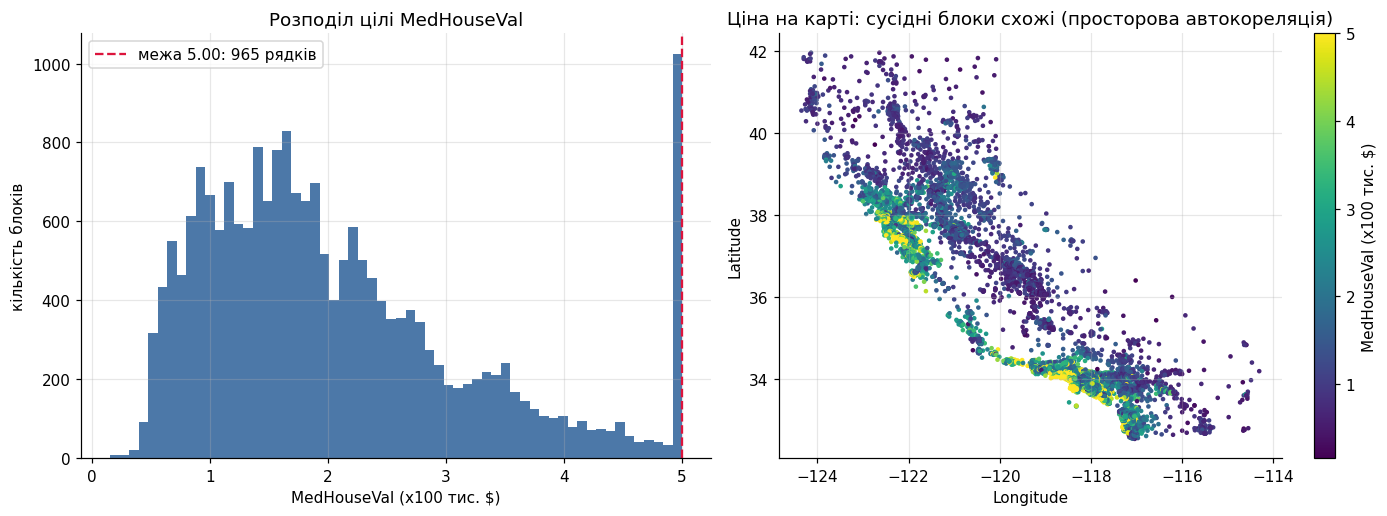

In [3]:
# Обрізана (цензурована) ціль та викиди
cap = df[TARGET].max()
n_cap = int((df[TARGET] >= cap - 1e-9).sum())
print(f"Максимум цілі: {cap:.5f}. Рядків із цим значенням: {n_cap} ({n_cap / len(df):.1%}) -> ціль обрізана зверху.")

print("\nКвантилі ознак із важкими хвостами:")
tails = pd.DataFrame({c: [df[c].median(), df[c].quantile(0.99), df[c].max()] for c in
                      ["AveRooms", "AveBedrms", "AveOccup", "Population"]},
                     index=["медіана", "99-й перцентиль", "максимум"]).T
print(tails.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].hist(df[TARGET], bins=60, color="#4c78a8")
ax[0].axvline(cap, color="crimson", ls="--", label=f"межа {cap:.2f}: {n_cap} рядків")
ax[0].set(title="Розподіл цілі MedHouseVal", xlabel="MedHouseVal (x100 тис. $)", ylabel="кількість блоків")
ax[0].legend()
sc = ax[1].scatter(df["Longitude"], df["Latitude"], c=df[TARGET], s=4, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label="MedHouseVal (x100 тис. $)")
ax[1].set(title="Ціна на карті: сусідні блоки схожі (просторова автокореляція)", xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
plt.savefig("figures/data_overview.png", bbox_inches="tight")
plt.show()

**Що видно і що з цим робимо.**
- Пропусків немає, усі ознаки числові, тому імпутація не потрібна.
- Ціль обрізана зверху (~5.0): ціни вище межі невідомі. Це занижує справжній розкид і створює систематичну недооцінку найдорожчих блоків; **ми не видаляємо ці рядки** (це змінило б задачу), а окремо аналізуємо помилки на них у розділі 8.
- У `AveRooms`, `AveBedrms`, `AveOccup`, `Population` є екстремальні викиди. Це реальні, хоч і незвичні блоки (курорти, готелі, студентські містечка), тому **викиди не прибираємо**. Дерева до них стійкі, а лінійні моделі можуть бути чутливі, і це враховуємо в інтерпретації.
- Карта показує сильну просторову структуру цін: саме це робить випадковий поділ потенційно «надто легким».

## 2. Створення «регіонів» для просторового поділу
У наборі немає стовпця «регіон», тому створюємо його кластеризацією **KMeans за `Latitude` та `Longitude`** (k = 15, `n_init=10`, фіксований сід). Це дає компактні географічні області приблизно однакового масштабу.

Застереження: регіони штучні (не адміністративні), KMeans працює в градусах, а не в кілометрах, а розміри груп нерівні. Вплив вибору k перевіряємо в розділі 5.

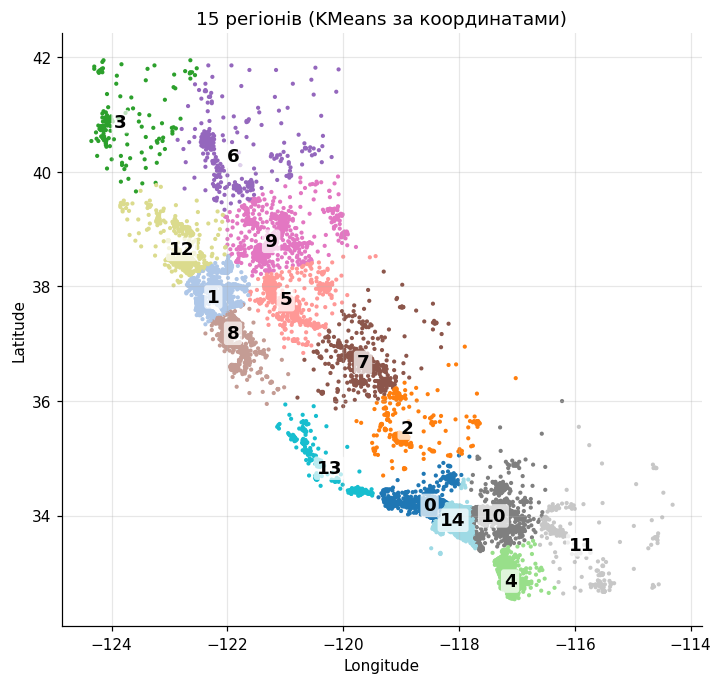

In [4]:
N_REGIONS = 15


def make_regions(k):
    return KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(df[["Latitude", "Longitude"]])


df["RegionGroup"] = make_regions(N_REGIONS)

region_summary = (df.groupby("RegionGroup")
                  .agg(n=(TARGET, "size"), mean_target=(TARGET, "mean"), std_target=(TARGET, "std"),
                       lat=("Latitude", "mean"), lon=("Longitude", "mean"))
                  .round(3))
region_summary["share"] = (region_summary["n"] / len(df)).round(3)
print(region_summary.to_string())

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(df["Longitude"], df["Latitude"], c=df["RegionGroup"], cmap="tab20", s=3)
for g, row in region_summary.iterrows():
    ax.text(row["lon"], row["lat"], str(g), fontsize=12, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.7, lw=0))
ax.set(title=f"{N_REGIONS} регіонів (KMeans за координатами)", xlabel="Longitude", ylabel="Latitude")
plt.savefig("figures/regions_map.png", bbox_inches="tight")
plt.show()

## 3. Базова лінія, попередня обробка та моделі

**Базові лінії** (щоб будь-яке покращення мало з чим порівнюватись):
- `DummyRegressor(mean)`: постійне передбачення середнього. Це нижня межа: R² ≈ 0.
- `LinearRegression` зі стандартизацією: проста лінійна базова лінія.

**Кандидати (3):**

| Модель | Навіщо вона тут |
|---|---|
| `Ridge` (alpha=1.0) | Інтерпретована лінійна модель із регуляризацією. Показує, скільки дає лінійна залежність без підбору. Параметр за замовчуванням, підбір не робили (чесно фіксуємо в обмеженнях). |
| `RandomForestRegressor` (50 дерев) | Нелінійна модель із усередненням. 50 дерев для швидкості на ноутбуці. Здатна «запам'ятовувати» локальну структуру, тому цікава для питання про просторову валідацію. |
| `HistGradientBoostingRegressor` | Сучасний сильний градієнтний бустинг для табличних даних. Швидкий і зазвичай найкращий на цьому датасеті. |

**Попередня обробка.** Єдиний крок, що навчається на даних, — `StandardScaler`, і лише для лінійних моделей (дереву масштабування не потрібне). Він стоїть **всередині `Pipeline`**, тому в кожному фолді налаштовується лише на train-частині, тож витоку немає. Для кожної моделі в кожному фолді виконується `clone(model).fit(train)` → `predict(test)`.

In [5]:
X = df[FEATURES]
y = df[TARGET]
groups = df["RegionGroup"].to_numpy()

models = {
    "Dummy (Baseline)": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("scaler", StandardScaler()), ("reg", LinearRegression())]),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("reg", Ridge(alpha=1.0, random_state=RANDOM_STATE))]),
    "Random Forest": RandomForestRegressor(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
print("Моделі:", list(models))
print("Ознаки:", FEATURES)

Моделі: ['Dummy (Baseline)', 'Linear Regression', 'Ridge', 'Random Forest', 'HistGradientBoosting']
Ознаки: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## 4. Схеми валідації та порівняння

Усі моделі оцінюємо у **трьох схемах** по 5 фолдів:

1. **`KFold (Random)`** — перемішаний випадковий поділ (класичний підхід).
2. **`GroupKFold (Spatial)`** — цілі регіони (KMeans-групи) потрапляють або в train, або в test, але не в обидва. Це імітує задачу «прогноз для нового регіону».
3. **`GroupKFold (Random groups, control)`** — **контроль**: ті самі розміри груп, але мітки груп випадково переставлені, тож географії в них немає. Фолди мають таку саму форму й розмір, як у просторовій схемі.

Навіщо контроль: у `GroupKFold` фолди нерівні й можуть бути просто «складнішими». Якщо різниця між (1) і (2) є, а між (1) і (3) ні, то причина — саме географія.

Метрики: **RMSE** (у тих самих одиницях, що ціна, штрафує великі помилки), **MAE** (типова помилка, стійка до викидів), **R²** (частка поясненої дисперсії; може бути від'ємним для поганих моделей).

In [6]:
def evaluate(model, X, y, splits):
    # Навчає клон моделі на кожному train-фолді, оцінює на test-фолді; повертає метрики по фолдах і OOF-передбачення.
    rows, oof = [], np.full(len(y), np.nan)
    for fold, (tr, te) in enumerate(splits):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        pred = m.predict(X.iloc[te])
        oof[te] = pred
        rows.append(dict(fold=fold, n_test=len(te),
                         RMSE=float(np.sqrt(mean_squared_error(y.iloc[te], pred))),
                         MAE=float(mean_absolute_error(y.iloc[te], pred)),
                         R2=float(r2_score(y.iloc[te], pred))))
    return pd.DataFrame(rows), oof


# контроль: переставляємо мітки груп -> ті самі розміри груп, але без географії
rng = np.random.default_rng(RANDOM_STATE)
random_groups = rng.permutation(groups)

SCHEMES = {
    "KFold (Random)": list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X)),
    "GroupKFold (Spatial)": list(GroupKFold(n_splits=5).split(X, y, groups)),
    "GroupKFold (Random groups, control)": list(GroupKFold(n_splits=5).split(X, y, random_groups)),
}

print("Розміри тестових фолдів:")
for s, splits in SCHEMES.items():
    print(f"  {s:38s}", [len(te) for _, te in splits])

# перевірка відсутності перетину груп між train і test у групових схемах
for s, g in [("GroupKFold (Spatial)", groups), ("GroupKFold (Random groups, control)", random_groups)]:
    for tr, te in SCHEMES[s]:
        assert set(g[tr]).isdisjoint(set(g[te])), "група потрапила і в train, і в test!"
print("Перевірка: у групових схемах жодна група не перетинається між train і test.")

Розміри тестових фолдів:
  KFold (Random)                         [4128, 4128, 4128, 4128, 4128]
  GroupKFold (Spatial)                   [5168, 3818, 3946, 3855, 3853]
  GroupKFold (Random groups, control)    [5168, 3818, 3946, 3855, 3853]
Перевірка: у групових схемах жодна група не перетинається між train і test.


In [7]:
per_fold, oof_store = [], {}
for scheme, splits in SCHEMES.items():
    for name, model in models.items():
        res, oof = evaluate(model, X, y, splits)
        res.insert(0, "Scheme", scheme)
        res.insert(0, "Model", name)
        per_fold.append(res)
        if name == "HistGradientBoosting":
            oof_store[scheme] = oof
per_fold = pd.concat(per_fold, ignore_index=True)
per_fold.to_csv("results/cv_per_fold.csv", index=False)

summary = (per_fold.groupby(["Scheme", "Model"], sort=False)
           .agg(RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", lambda s: s.to_numpy().std()),
                MAE_mean=("MAE", "mean"), MAE_std=("MAE", lambda s: s.to_numpy().std()),
                R2_mean=("R2", "mean"), R2_std=("R2", lambda s: s.to_numpy().std()))
           .reset_index()[["Model", "Scheme", "RMSE_mean", "RMSE_std", "MAE_mean", "MAE_std", "R2_mean", "R2_std"]])
summary.to_csv("results/model_comparison.csv", index=False)

print("--- ПОРІВНЯННЯ КРОС-ВАЛІДАЦІЇ (середнє та std по 5 фолдах) ---")
print(summary.round(4).to_string(index=False))

--- ПОРІВНЯННЯ КРОС-ВАЛІДАЦІЇ (середнє та std по 5 фолдах) ---
               Model                              Scheme  RMSE_mean  RMSE_std  MAE_mean  MAE_std  R2_mean  R2_std
    Dummy (Baseline)                      KFold (Random)     1.1539    0.0103    0.9118   0.0067  -0.0003  0.0003
   Linear Regression                      KFold (Random)     0.7283    0.0149    0.5317   0.0084   0.6014  0.0170
               Ridge                      KFold (Random)     0.7282    0.0149    0.5317   0.0084   0.6014  0.0170
       Random Forest                      KFold (Random)     0.5062    0.0085    0.3299   0.0065   0.8075  0.0066
HistGradientBoosting                      KFold (Random)     0.4669    0.0103    0.3123   0.0059   0.8361  0.0079
    Dummy (Baseline)                GroupKFold (Spatial)     1.1774    0.1106    0.9412   0.1185  -0.1688  0.2790
   Linear Regression                GroupKFold (Spatial)     0.7379    0.0937    0.5460   0.0658   0.5495  0.0682
               Ridge     

In [8]:
# Наскільки погіршується оцінка при зміні схеми? Порівнюємо різницю з розкидом по фолдах.
piv_m = summary.pivot(index="Model", columns="Scheme", values="RMSE_mean").loc[list(models)]
piv_s = summary.pivot(index="Model", columns="Scheme", values="RMSE_std").loc[list(models)]
r, sp, ct = "KFold (Random)", "GroupKFold (Spatial)", "GroupKFold (Random groups, control)"

gap = pd.DataFrame({
    "RMSE random": piv_m[r],
    "RMSE spatial": piv_m[sp],
    "RMSE control": piv_m[ct],
    "d spatial-random": piv_m[sp] - piv_m[r],
    "d %": 100 * (piv_m[sp] - piv_m[r]) / piv_m[r],
    "d control-random": piv_m[ct] - piv_m[r],
    "std spatial": piv_s[sp],
})
print("Зсув RMSE при переході на просторову схему (d = різниця, % = відносна зміна):")
print(gap.round(4).to_string())
gap.to_csv("results/validation_gap.csv")

# Парне порівняння по фолдах: скільки фолдів HGB краще за Ridge та за Random Forest
pf = per_fold.pivot_table(index=["Scheme", "fold"], columns="Model", values="RMSE")
print("\nУ скількох із 5 фолдів HGB має менший RMSE, ніж інша модель:")
for s in SCHEMES:
    t = pf.loc[s]
    print(f"  {s:38s} vs Ridge: {(t['HistGradientBoosting'] < t['Ridge']).sum()}/5 | "
          f"vs Random Forest: {(t['HistGradientBoosting'] < t['Random Forest']).sum()}/5")

Зсув RMSE при переході на просторову схему (d = різниця, % = відносна зміна):
                      RMSE random  RMSE spatial  RMSE control  d spatial-random      d %  d control-random  std spatial
Model                                                                                                                  
Dummy (Baseline)           1.1539        1.1774        1.1543            0.0234   2.0298            0.0003       0.1106
Linear Regression          0.7283        0.7379        0.7258            0.0096   1.3204           -0.0024       0.0937
Ridge                      0.7282        0.7378        0.7258            0.0096   1.3178           -0.0024       0.0938
Random Forest              0.5062        0.7267        0.5071            0.2205  43.5659            0.0010       0.1316
HistGradientBoosting       0.4669        0.6572        0.4655            0.1903  40.7584           -0.0014       0.0926

У скількох із 5 фолдів HGB має менший RMSE, ніж інша модель:
  KFold (Random)    

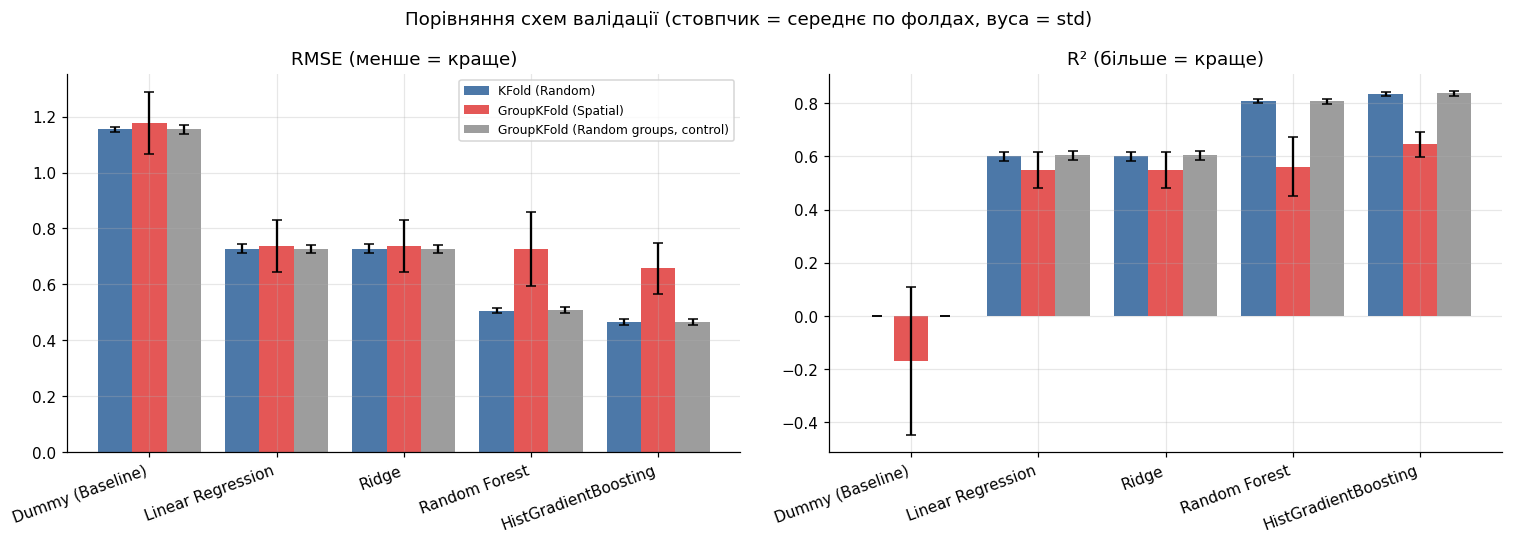

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
names = list(models)
xpos = np.arange(len(names))
w = 0.27
colors = {r: "#4c78a8", sp: "#e45756", ct: "#9d9d9d"}
for j, s in enumerate([r, sp, ct]):
    d = summary[summary["Scheme"] == s].set_index("Model").loc[names]
    ax[0].bar(xpos + (j - 1) * w, d["RMSE_mean"], w, yerr=d["RMSE_std"], capsize=3, label=s, color=colors[s])
    ax[1].bar(xpos + (j - 1) * w, d["R2_mean"], w, yerr=d["R2_std"], capsize=3, label=s, color=colors[s])
for a, t in zip(ax, ["RMSE (менше = краще)", "R² (більше = краще)"]):
    a.set_xticks(xpos)
    a.set_xticklabels(names, rotation=20, ha="right")
    a.set_title(t)
ax[0].legend(fontsize=8)
plt.suptitle("Порівняння схем валідації (стовпчик = середнє по фолдах, вуса = std)")
plt.tight_layout()
plt.savefig("figures/cv_comparison.png", bbox_inches="tight")
plt.show()

**Як читати.** Порівнюйте три стовпчики для кожної моделі: якщо червоний (просторова схема) помітно вищий за синій (випадкова), а сірий (контроль) близький до синього, то погіршення спричинене саме географією, а не «важчими» фолдами. Різниці, менші за std по фолдах, слід вважати недостовірними (фолдів лише 5, а розмір тестових частин нерівний). Інтерпретацію з конкретними числами записано в `README.md`.

## 5. Чутливість до числа регіонів k
Результат просторової валідації залежить від того, як ми нарізали регіони. Перевіряємо k ∈ {5, 10, 15, 20, 30} для двох моделей: лінійної (`Ridge`) та найкращої (`HistGradientBoosting`). Пунктир — оцінка при випадковому `KFold`.

In [2]:
rows = []
for k in [5, 10, 15, 20, 30]:
    g = groups if k == N_REGIONS else make_regions(k)
    splits = list(GroupKFold(n_splits=5).split(X, y, g))
    for name in ["Ridge", "HistGradientBoosting"]:
        res, _ = evaluate(models[name], X, y, splits)
        rows.append(dict(k=k, Model=name, RMSE_mean=res["RMSE"].mean(), RMSE_std=res["RMSE"].to_numpy().std(),
                         R2_mean=res["R2"].mean()))
sens = pd.DataFrame(rows)
sens.to_csv("results/sensitivity_k.csv", index=False)
print(sens.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, c in [("Ridge", "#4c78a8"), ("HistGradientBoosting", "#e45756")]:
    d = sens[sens["Model"] == name]
    ax.errorbar(d["k"], d["RMSE_mean"], yerr=d["RMSE_std"], marker="o", capsize=3, color=c, label=f"{name}: GroupKFold")
    base = summary[(summary["Model"] == name) & (summary["Scheme"] == r)]["RMSE_mean"].iloc[0]
    ax.axhline(base, ls=":", color=c, label=f"{name}: KFold (random)")
ax.set(xlabel="кількість регіонів k", ylabel="RMSE", title="Чутливість просторової оцінки до k")
ax.legend(fontsize=8)
plt.savefig("figures/sensitivity_k.png", bbox_inches="tight")
plt.show()

NameError: name 'N_REGIONS' is not defined

## 6. Абляція: що буде без координат?
Модель із `Latitude`/`Longitude` може «запам'ятовувати» місцевість. Перевіряємо, як змінюється різниця між схемами, якщо прибрати координати з ознак (регіональні групи для поділу лишаються тими самими).

In [ ]:
X_nc = X.drop(columns=["Latitude", "Longitude"])
rows = []
for scheme in [r, sp]:
    for name in ["Ridge", "HistGradientBoosting"]:
        for label, XX in [("з координатами", X), ("без координат", X_nc)]:
            res, _ = evaluate(models[name], XX, y, SCHEMES[scheme])
            rows.append(dict(Model=name, Features=label, Scheme=scheme, RMSE_mean=res["RMSE"].mean(),
                             RMSE_std=res["RMSE"].to_numpy().std(), R2_mean=res["R2"].mean()))
abl = pd.DataFrame(rows)
abl.to_csv("results/ablation_no_coords.csv", index=False)
print(abl.round(4).to_string(index=False))

abl_p = abl.pivot_table(index=["Model", "Features"], columns="Scheme", values="RMSE_mean")
abl_p["d spatial-random"] = abl_p[sp] - abl_p[r]
print("\nРізниця просторової та випадкової схеми (RMSE):")
print(abl_p[["d spatial-random"]].round(4).to_string())

## 7. Permutation importance на відкладених фолдах
Для найкращої моделі (`HistGradientBoosting`) у **кожному фолді**: навчаємо на train, потім на **test-частині** по черзі перемішуємо кожну ознаку (`n_repeats=10`) і вимірюємо, наскільки зростає RMSE. Рахуємо це в обох схемах (випадковій і просторовій), тож видно, чи залежить рейтинг ознак від схеми валідації.

- Важливість = **зростання RMSE** (в одиницях 100 тис. $) при перемішуванні ознаки: більше = ознака важливіша.
- Розкид = std середніх по фолдах.
- `Latitude` і `Longitude` разом задають місце. Якщо перемішувати кожну окремо, виникають неможливі пари (широта одного міста + довгота іншого, десь в океані), і це може *завищувати* важливість кожної. Тому додатково рахуємо **спільне перемішування пари** (`Lat+Lon (joint)`: одна й та сама перестановка рядків для обох, пара лишається реальним місцем) — це вимірює цінність «місця» загалом. Ці три рядки порівнюємо між собою обережно.

In [ ]:
def perm_importance_folds(model, X, y, splits, n_repeats=10):
    per_fold_imp, per_fold_joint = [], []
    for fold, (tr, te) in enumerate(splits):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        Xte, yte = X.iloc[te], y.iloc[te]
        res = permutation_importance(m, Xte, yte, scoring="neg_root_mean_squared_error",
                                     n_repeats=n_repeats, random_state=RANDOM_STATE)
        per_fold_imp.append(res.importances_mean)             # = зростання RMSE
        base = np.sqrt(mean_squared_error(yte, m.predict(Xte)))
        rs = np.random.default_rng(RANDOM_STATE + fold)
        geo = Xte[["Latitude", "Longitude"]].to_numpy()
        inc = []
        for _ in range(n_repeats):
            Xp = Xte.copy()
            Xp[["Latitude", "Longitude"]] = geo[rs.permutation(len(te))]
            inc.append(np.sqrt(mean_squared_error(yte, m.predict(Xp))) - base)
        per_fold_joint.append(np.mean(inc))
    return np.array(per_fold_imp), np.array(per_fold_joint)


hgb = models["HistGradientBoosting"]
imp_rows = []
for scheme in [r, sp]:
    imp, joint = perm_importance_folds(hgb, X, y, SCHEMES[scheme])
    for i, f in enumerate(FEATURES):
        imp_rows.append(dict(Scheme=scheme, Feature=f, Importance_mean=imp[:, i].mean(), Importance_std=imp[:, i].std()))
    imp_rows.append(dict(Scheme=scheme, Feature="Lat+Lon (joint)", Importance_mean=joint.mean(), Importance_std=joint.std()))
imp_df = pd.DataFrame(imp_rows)
imp_df.to_csv("results/permutation_importance.csv", index=False)

tab = imp_df.pivot(index="Feature", columns="Scheme", values="Importance_mean")[[r, sp]].sort_values(r, ascending=False)
tab["rank random"] = tab[r].rank(ascending=False).astype(int)
tab["rank spatial"] = tab[sp].rank(ascending=False).astype(int)
print("Важливість = зростання RMSE при перемішуванні ознаки (на тестових фолдах):")
print(tab.round(4).to_string())

In [ ]:
order = imp_df[imp_df["Scheme"] == r].sort_values("Importance_mean")["Feature"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True, sharex=True)
for a, s, c in zip(ax, [r, sp], ["#4c78a8", "#e45756"]):
    d = imp_df[imp_df["Scheme"] == s].set_index("Feature").loc[order]
    a.barh(order, d["Importance_mean"], xerr=d["Importance_std"], color=c, capsize=3)
    a.set_title(s)
    a.set_xlabel("зростання RMSE при перемішуванні (x100 тис. $)")
plt.suptitle("Permutation importance, HistGradientBoosting, відкладені фолди (вуса = std по фолдах)")
plt.tight_layout()
plt.savefig("figures/permutation_importance.png", bbox_inches="tight")
plt.show()

**Як читати.** Якщо координати лідирують при `KFold`, але їхня вага падає при `GroupKFold`, то модель при випадковому поділі в значній мірі «впізнає місцевість», що відповідає висновку про оптимістичну випадкову валідацію. Важливість `Latitude`/`Longitude` дивимось разом із `Lat+Lon (joint)`: окремі стовпчики координат не додаються арифметично (вони пов'язані). Конкретні числа та висновок — у `README.md`.

## 8. Аналіз помилок
Беремо **out-of-fold передбачення** `HistGradientBoosting` при просторовій валідації (кожен блок передбачений моделлю, яка не бачила його регіону). Питання: **де** модель помиляється і **чому**?

In [ ]:
CITIES = {"San Francisco": (37.77, -122.42), "Oakland": (37.80, -122.27), "San Jose": (37.34, -121.89),
          "Sacramento": (38.58, -121.49), "Los Angeles": (34.05, -118.24), "San Diego": (32.72, -117.16),
          "Santa Barbara": (34.42, -119.70), "Fresno": (36.74, -119.79), "Bakersfield": (35.37, -119.02),
          "Monterey": (36.60, -121.89), "Palm Springs": (33.83, -116.55), "Lake Tahoe": (39.10, -120.03),
          "Redding": (40.59, -122.39), "Eureka": (40.80, -124.16)}
city_names = list(CITIES)
city_xy = np.array([CITIES[c] for c in city_names])


def nearest_city(lat, lon):
    # найближче велике місто та відстань у км (haversine)
    lat, lon = np.radians(np.asarray(lat, float))[:, None], np.radians(np.asarray(lon, float))[:, None]
    clat, clon = np.radians(city_xy[:, 0])[None, :], np.radians(city_xy[:, 1])[None, :]
    a = np.sin((clat - lat) / 2) ** 2 + np.cos(lat) * np.cos(clat) * np.sin((clon - lon) / 2) ** 2
    d = 2 * 6371 * np.arcsin(np.sqrt(a))
    idx = d.argmin(axis=1)
    return np.array(city_names)[idx], d[np.arange(len(idx)), idx]


err = df.copy()
err["pred"] = oof_store[sp]
err["pred_random"] = oof_store[r]
assert not err["pred"].isna().any() and not err["pred_random"].isna().any()
err["resid"] = err[TARGET] - err["pred"]                 # >0: модель недооцінює
err["abs_err"] = err["resid"].abs()
err["abs_err_random"] = (err[TARGET] - err["pred_random"]).abs()
err["capped"] = err[TARGET] >= cap - 1e-9
err["city"], err["city_km"] = nearest_city(err["Latitude"], err["Longitude"])

print(f"Загальні: RMSE={np.sqrt((err['resid'] ** 2).mean()):.4f}  MAE={err['abs_err'].mean():.4f}  (просторова схема, OOF)")

In [ ]:
# 8.1 Помилки по регіонах
def rmse(s):
    return float(np.sqrt((s ** 2).mean()))


by_region = (err.groupby("RegionGroup")
             .apply(lambda d: pd.Series({
                 "n": len(d), "mean_target": d[TARGET].mean(),
                 "RMSE_spatial": rmse(d["resid"]),
                 "RMSE_random": rmse(d[TARGET] - d["pred_random"]),
                 "MAE_spatial": d["abs_err"].mean(),
                 "bias (y-pred)": d["resid"].mean(),
                 "share_capped": d["capped"].mean()}), include_groups=False)
             .join(region_summary[["lat", "lon"]]))
by_region["RMSE_penalty"] = by_region["RMSE_spatial"] - by_region["RMSE_random"]
reg_city, reg_km = nearest_city(by_region["lat"], by_region["lon"])
by_region["nearest_city"] = reg_city
by_region["km"] = reg_km.round(0)
by_region = by_region.sort_values("RMSE_spatial", ascending=False).round(3)
by_region.to_csv("results/errors_by_region.csv")
print(by_region.to_string())

In [ ]:
# 8.2 Карта помилок та регіональні діагностики
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
e = err.sort_values("abs_err")
sc = ax[0].scatter(e["Longitude"], e["Latitude"], c=e["abs_err"], s=5, cmap="magma_r", vmax=np.quantile(e["abs_err"], 0.995))
plt.colorbar(sc, ax=ax[0], label="|помилка| (x100 тис. $)")
ax[0].set(title="Абсолютна помилка (OOF, просторова валідація)", xlabel="Longitude", ylabel="Latitude")

sc2 = ax[1].scatter(e["Longitude"], e["Latitude"], c=e["resid"], s=5, cmap="coolwarm", vmin=-1.5, vmax=1.5)
plt.colorbar(sc2, ax=ax[1], label="y - pred (>0: недооцінка)")
ax[1].set(title="Зсув (залишки): червоне = модель занижує ціну", xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
plt.savefig("figures/spatial_errors.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
br = by_region.sort_values("RMSE_spatial")
ax[0].barh(br.index.astype(str), br["RMSE_random"], height=0.4, label="KFold (random)", color="#4c78a8", align="edge")
ax[0].barh(br.index.astype(str), br["RMSE_spatial"], height=-0.4, label="GroupKFold (spatial)", color="#e45756", align="edge")
ax[0].set(title="RMSE по регіонах (HGB)", xlabel="RMSE", ylabel="RegionGroup")
ax[0].legend(fontsize=8)

hb = ax[1].hexbin(err[TARGET], err["pred"], gridsize=45, cmap="viridis", mincnt=1, bins="log")
ax[1].plot([0, 5.2], [0, 5.2], "r--", lw=1)
ax[1].axvline(cap, color="grey", ls=":")
ax[1].set(title="Факт vs прогноз (OOF)", xlabel="факт", ylabel="прогноз")

bins = [0, 1, 2, 3, 4, 5, 6]
err["target_bin"] = pd.cut(err[TARGET], bins=bins, right=False, labels=["[0,1)", "[1,2)", "[2,3)", "[3,4)", "[4,5)", "5.0 (обрізано)"])
bb = err.groupby("target_bin", observed=True)["resid"].agg(["mean", "size"])
ax[2].bar(bb.index.astype(str), bb["mean"], color="#f58518")
ax[2].axhline(0, color="k", lw=0.8)
ax[2].set(title="Середній зсув залишків за рівнем фактичної ціни", ylabel="y - pred")
ax[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("figures/error_diagnostics.png", bbox_inches="tight")
plt.show()
print(bb.round(3).to_string())

In [ ]:
# 8.3 Обрізана ціль, найгірші передбачення, патерни
cap_mask = err["capped"]
print(f"RMSE на блоках із обрізаною ціллю (n={int(cap_mask.sum())}): {rmse(err.loc[cap_mask, 'resid']):.3f}; "
      f"зсув (y-pred): {err.loc[cap_mask, 'resid'].mean():+.3f}")
print(f"RMSE на решті (n={int((~cap_mask).sum())}): {rmse(err.loc[~cap_mask, 'resid']):.3f}; "
      f"зсув: {err.loc[~cap_mask, 'resid'].mean():+.3f}")

thr = err["abs_err"].quantile(0.99)
top = err[err["abs_err"] >= thr]
print(f"\nНайгірший 1% помилок (|err| >= {thr:.2f}, n={len(top)}):")
print(f"  частка блоків із обрізаною ціллю: {top['capped'].mean():.1%} (у всій вибірці: {cap_mask.mean():.1%})")
print(f"  частка, де модель занижує ціну (y>pred): {(top['resid'] > 0).mean():.1%}")
cmp_cols = ["MedInc", "HouseAge", "AveRooms", "AveOccup", "Population"]
print("\nМедіани ознак: найгірший 1% проти всіх блоків")
print(pd.DataFrame({"top 1%": top[cmp_cols].median(), "усі": err[cmp_cols].median()}).round(2).to_string())
print("\nНайближче велике місто для найгірших блоків (км <= 40 вважаємо «місто»):")
tc = top.assign(near=np.where(top["city_km"] <= 40, top["city"], "поза містами")).groupby("near").size().sort_values(ascending=False)
print(tc.to_string())

worst = err.nlargest(15, "abs_err")[["Latitude", "Longitude", "RegionGroup", "city", "city_km", "MedInc", "HouseAge",
                                       "AveRooms", "AveOccup", "Population", TARGET, "pred", "resid"]].round(3)
worst.to_csv("results/worst_predictions.csv", index=False)
print("\n15 найгірших передбачень:")
print(worst.to_string(index=False))

## 9. Підсумок ключових чисел для README
Наступна комірка збирає ключові числа в `results/summary.md` і друкує їх: саме з них пишуться висновки в `README.md`.

In [ ]:
lines = []
lines.append("# Ключові числа (генерується main.ipynb)\n")
lines.append("## Зсув RMSE: випадкова -> просторова схема\n```\n" + gap.round(4).to_string() + "\n```\n")

hg = gap.loc["HistGradientBoosting"]
lines.append(f"HGB: RMSE {hg['RMSE random']:.3f} -> {hg['RMSE spatial']:.3f} (+{hg['d %']:.0f}%), "
             f"контроль (випадкові групи) = {hg['RMSE control']:.3f}\n")

lines.append("## Чутливість до k\n```\n" + sens.round(4).to_string(index=False) + "\n```\n")
lines.append("## Абляція без координат\n```\n" + abl.round(4).to_string(index=False) + "\n```\n")
lines.append("## Permutation importance (зростання RMSE)\n```\n" + tab.round(4).to_string() + "\n```\n")

worst_regions = by_region.head(3)[["n", "RMSE_spatial", "bias (y-pred)", "nearest_city", "km"]]
lines.append("## Найгірші регіони за RMSE (просторова схема)\n```\n" + worst_regions.to_string() + "\n```\n")
lines.append(f"## Обрізана ціль\nRMSE (обрізані) = {rmse(err.loc[cap_mask, 'resid']):.3f}, "
             f"зсув = {err.loc[cap_mask, 'resid'].mean():+.3f}; "
             f"частка обрізаних у найгіршому 1% = {top['capped'].mean():.1%}\n")

text = "\n".join(lines)
with open("results/summary.md", "w", encoding="utf-8") as f:
    f.write(text)
print(text)

## 10. Обмеження (що ці результати НЕ підтверджують)
- **Регіони штучні.** KMeans за координатами дає не адміністративні межі. Кількість і форма регіонів впливають на результат (розділ 5), а групи нерівні за розміром, тому в `GroupKFold` фолди нерівні й дають великий розкид (std). Фолдів лише 5.
- **Просторова валідація ≠ «справжній» прогноз для нового штату.** Ми перевіряємо екстраполяцію на відокремлені області всередині Каліфорнії, а не на інші ринки.
- **Дані 1990 року**, ознаки агреговані по «блоках» (не окремі будинки) — результати не переносяться на сучасний ринок.
- **Ціна обрізана зверху (~5.0).** Метрики для найдорожчих блоків занижені, а недооцінка таких блоків частково є артефактом даних (розділ 8).
- **Гіперпараметри не підбирались** (Ridge alpha=1.0, RF 50 дерев, HGB за замовчуванням), тож ранжування моделей не є межею їхньої якості; порівнюємо схеми валідації, а не змагаємось за точність.
- **Permutation importance** при сильно корельованих ознаках (Latitude/Longitude, AveRooms/AveBedrms) «ділить» важливість між ними. Тому для координат додано спільне перемішування пари. Важливість описує поведінку конкретної моделі, а не причинний вплив ознаки на ціну.
- **Додаткові експерименти (контроль, абляція, чутливість до k) — одна реалізація з одним сідом** (різні сіди не усереднювались).